## Initial Tony Grove Output
A quick initial look at output from Tony Grove to evaluate basic settings and model output.

In [1]:
import xarray as xr
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
# Output configuration
site = 'tonygrovers'
run_type = 'spinup_100y'
forcings = 's00000000'
forcing_build = 'v0.4.4'

### Assess land_daily

In [3]:
folder_path = f'C:/Users/clmbn/NMT_PhD/data/output/{site}/{site}_{run_type}_{forcings}_{forcing_build}/history/'

In [5]:
land_daily = xr.open_dataset(folder_path + '19091001.land_daily.nc')


In [11]:
land_month = xr.open_dataset(folder_path + '19091001.land_month.nc')

In [12]:
land_month

<xarray.Dataset> Size: 4MB
Dimensions:                  (grid_index: 1, time: 1200, nv: 2, lon: 1,
                              lonb: 2, lat: 1, latb: 2, zfull_soil: 20,
                              zhalf_soil: 21, band: 2)
Coordinates:
  * grid_index               (grid_index) float64 8B 0.0
  * time                     (time) object 10kB 1909-10-16 12:00:00 ... 2009-...
  * nv                       (nv) float64 16B 1.0 2.0
  * lon                      (lon) float64 8B -111.6
  * lonb                     (lonb) float64 16B -112.1 -111.1
  * lat                      (lat) float64 8B 41.89
  * latb                     (latb) float64 16B 41.39 42.39
  * zfull_soil               (zfull_soil) float64 160B 0.01 0.04 ... 6.75 8.75
  * zhalf_soil               (zhalf_soil) float64 168B 0.0 0.02 ... 7.5 10.0
  * band                     (band) float64 16B 1.0 2.0
    geolon_t                 (grid_index) float32 4B ...
    geolat_t                 (grid_index) float32 4B ...
Data variables: (12/221)
    soil_ice                 (time, zfull_soil, grid_index) float32 96kB ...
    soil_liq                 (time, zfull_soil, grid_index) float32 96kB ...
    soil_psi                 (time, zfull_soil, grid_index) float32 96kB ...
    soil_T                   (time, zfull_soil, grid_index) float32 96kB ...
    soil_uptk                (time, zfull_soil, grid_index) float32 96kB ...
    albedo_dif               (time, band, grid_index) float32 10kB ...
    ...                       ...
    cwlitt_dmic_C_resp       (time, grid_index) float32 5kB ...
    Ctot                     (time, grid_index) float32 5kB ...
    average_T1               (time) datetime64[ns] 10kB ...
    average_T2               (time) datetime64[ns] 10kB ...
    average_DT               (time) timedelta64[ns] 10kB ...
    time_bnds                (time, nv) object 19kB ...
Attributes:
    filename:          land_month.nc
    title:             
    associated_files:  soil_area: land_static.nc land_area: land_static.nc
    grid_type:         regular
    grid_tile:         N/A

In [6]:
land_daily

<xarray.Dataset> Size: 13MB
Dimensions:                  (grid_index: 1, time: 36525, nv: 2, lon: 1,
                              lonb: 2, lat: 1, latb: 2, zfull_soil: 20,
                              zhalf_soil: 21, band: 2)
Coordinates:
  * grid_index               (grid_index) float64 8B 0.0
  * time                     (time) object 292kB 1909-10-01 12:00:00 ... 2009...
  * nv                       (nv) float64 16B 1.0 2.0
  * lon                      (lon) float64 8B -111.6
  * lonb                     (lonb) float64 16B -112.1 -111.1
  * lat                      (lat) float64 8B 41.89
  * latb                     (latb) float64 16B 41.39 42.39
  * zfull_soil               (zfull_soil) float64 160B 0.01 0.04 ... 6.75 8.75
  * zhalf_soil               (zhalf_soil) float64 168B 0.0 0.02 ... 7.5 10.0
  * band                     (band) float64 16B 1.0 2.0
    geolon_t                 (grid_index) float64 8B ...
    geolat_t                 (grid_index) float64 8B ...
Data variables: (12/56)
    fco2                     (time, grid_index) float32 146kB ...
    t_ref                    (time, grid_index) float32 146kB ...
    co2_mol_flux             (time, grid_index) float32 146kB ...
    co2_mol_flux1            (time, grid_index) float32 146kB ...
    btot                     (time, grid_index) float32 146kB ...
    Ctot                     (time, grid_index) float32 146kB ...
    ...                       ...
    drydep_md                (time, grid_index) float32 146kB ...
    drydep_om                (time, grid_index) float32 146kB ...
    average_T1               (time) datetime64[ns] 292kB ...
    average_T2               (time) datetime64[ns] 292kB ...
    average_DT               (time) timedelta64[ns] 292kB ...
    time_bnds                (time, nv) object 584kB ...
Attributes:
    filename:          land_daily.nc
    title:             
    associated_files:  soil_area: land_static.nc land_area: land_static.nc
    grid_type:         regular
    grid_tile:         N/A

The output time is middle of the day Julian. Will it be easy to convert?

Try extracting some data to dataframe

In [7]:
snow_data = land_daily[['snow','snow_depth','snow_density']].isel(grid_index=0).to_dataframe()

In [ ]:
snow_data

In [ ]:
snow_data.index

In [ ]:
# Convert the index to a datetime index
snow_data.index = snow_data.index.to_datetimeindex()

In [ ]:
snow_data['snow_depth'].plot()

### Assess some vegetation

In [17]:
vegetation_data = land_month[['height','lai']].isel(grid_index=0).to_dataframe()

In [18]:
vegetation_data.index = vegetation_data.index.to_datetimeindex()

C:\Users\clmbn\AppData\Local\Temp\ipykernel_10792\1682549718.py:1: RuntimeWarning: Converting a CFTimeIndex with dates from a non-standard calendar, 'julian', to a pandas.DatetimeIndex, which uses dates from the standard calendar.  This may lead to subtle errors in operations that depend on the length of time between dates.
  vegetation_data.index = vegetation_data.index.to_datetimeindex()


array([<Axes: >, <Axes: >], dtype=object)

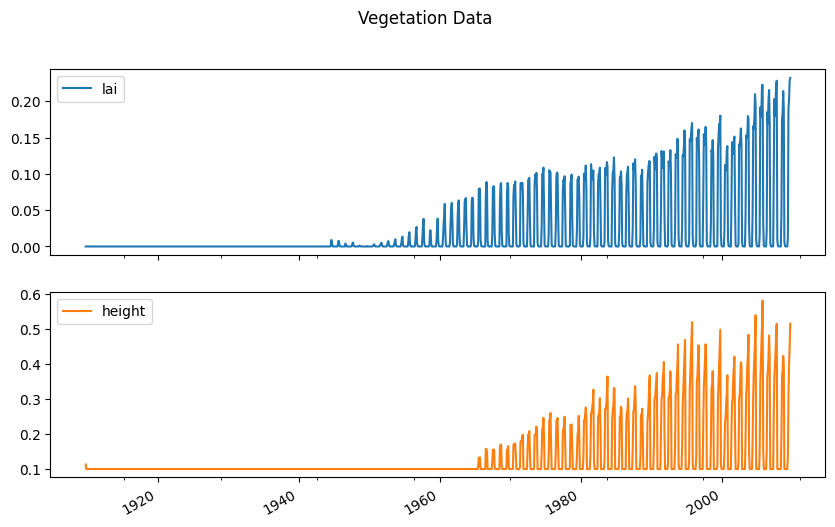

In [19]:
vegetation_data[['lai','height']].plot(subplots=True, figsize=(10, 6), title='Vegetation Data')

Total biomass starts at around 0 and increases as expected. It is not clear if a steady state is reached.

### Assess vegetation land_byspecies

In [ ]:
land_byspecies = xr.open_dataset(folder_path + '19991001.land_byspecies.nc')

In [ ]:
land_byspecies